In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import calendar
sns.set(style="whitegrid")

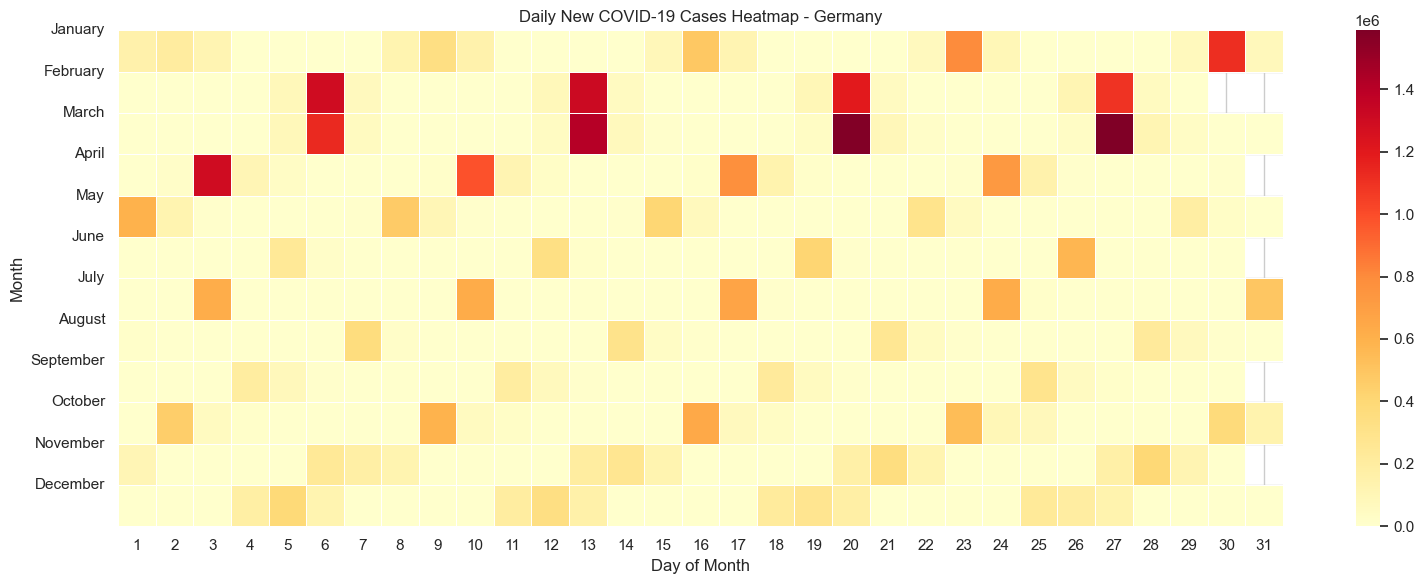

In [ ]:
dataset = pd.read_csv('europe_covid_cleaned.csv')

dataset['date'] = pd.to_datetime(dataset['date'])

def daily_cases_calendar_heatmap(country='Germany'):
    df = dataset[dataset['location'] == country].copy()
    df['year'] = df['date'].dt.year
    df['month'] = df['date'].dt.month
    df['day'] = df['date'].dt.day
    df_pivot = df.pivot_table(index='month', columns='day', values='new_cases', aggfunc='sum')

    plt.figure(figsize=(16, 6))
    sns.heatmap(df_pivot, cmap="YlOrRd", linewidths=0.5)
    plt.title(f'Daily New COVID-19 Cases Heatmap - {country}')
    plt.ylabel('Month')
    plt.yticks(ticks=[i-1 for i in range(1,13)], labels=calendar.month_name[1:], rotation=0)
    plt.xlabel('Day of Month')
    plt.tight_layout()
    plt.show()

daily_cases_calendar_heatmap('Germany')


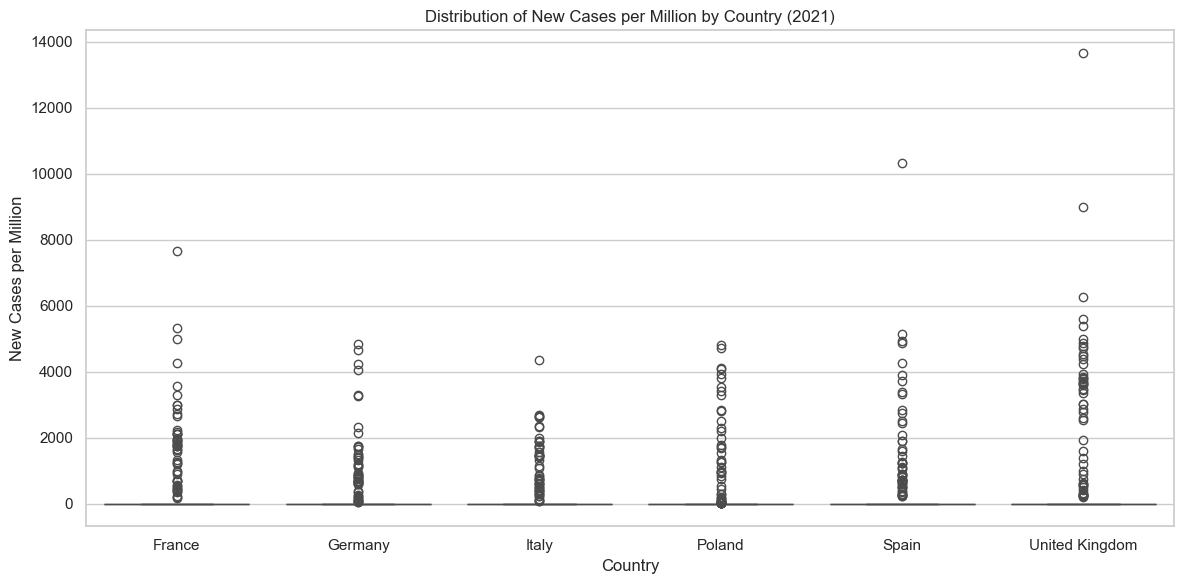

In [ ]:
df = pd.read_csv('europe_covid_cleaned.csv', usecols=['location', 'date', 'new_cases_per_million'])
df['date'] = pd.to_datetime(df['date'])
df = df[df['date'].dt.year == 2021]

selected_countries = ['Germany', 'Italy', 'France', 'Poland', 'Spain', 'United Kingdom']
df = df[df['location'].isin(selected_countries)]

plt.figure(figsize=(12, 6))
sns.boxplot(data=df, x='location', y='new_cases_per_million')
plt.title('Distribution of New Cases per Million by Country (2021)')
plt.xlabel('Country')
plt.ylabel('New Cases per Million')
plt.tight_layout()
plt.show()



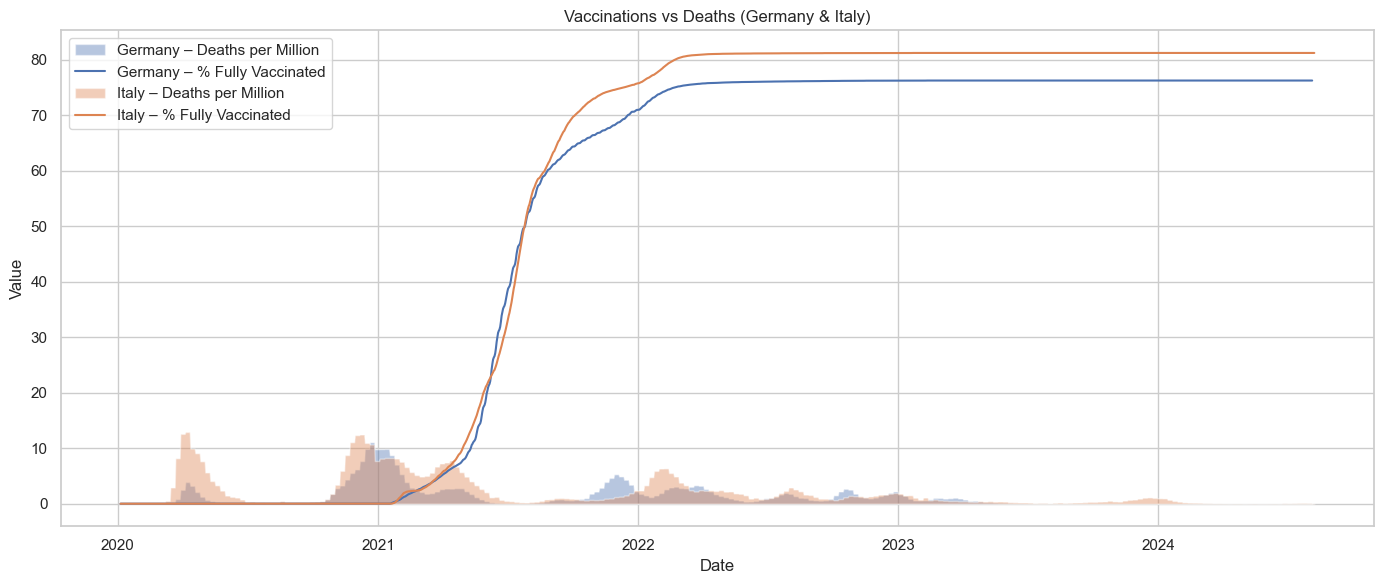

In [ ]:
df = pd.read_csv('europe_covid_cleaned.csv', usecols=['location', 'date', 'people_fully_vaccinated_per_hundred', 'new_deaths_per_million'])
df = df[df['location'].isin(['Germany', 'Italy'])].copy()
df['date'] = pd.to_datetime(df['date'])

df['vaccinated'] = df['people_fully_vaccinated_per_hundred'].fillna(method='ffill')
df['deaths'] = df['new_deaths_per_million'].rolling(window=7).mean()

plt.figure(figsize=(14, 6))
for country in ['Germany', 'Italy']:
    sub = df[df['location'] == country]
    plt.fill_between(sub['date'], sub['deaths'], label=f'{country} – Deaths per Million', alpha=0.4)
    plt.plot(sub['date'], sub['vaccinated'], label=f'{country} – % Fully Vaccinated')

plt.legend()
plt.title('Vaccinations vs Deaths (Germany & Italy)')
plt.xlabel('Date')
plt.ylabel('Value')
plt.tight_layout()
plt.show()


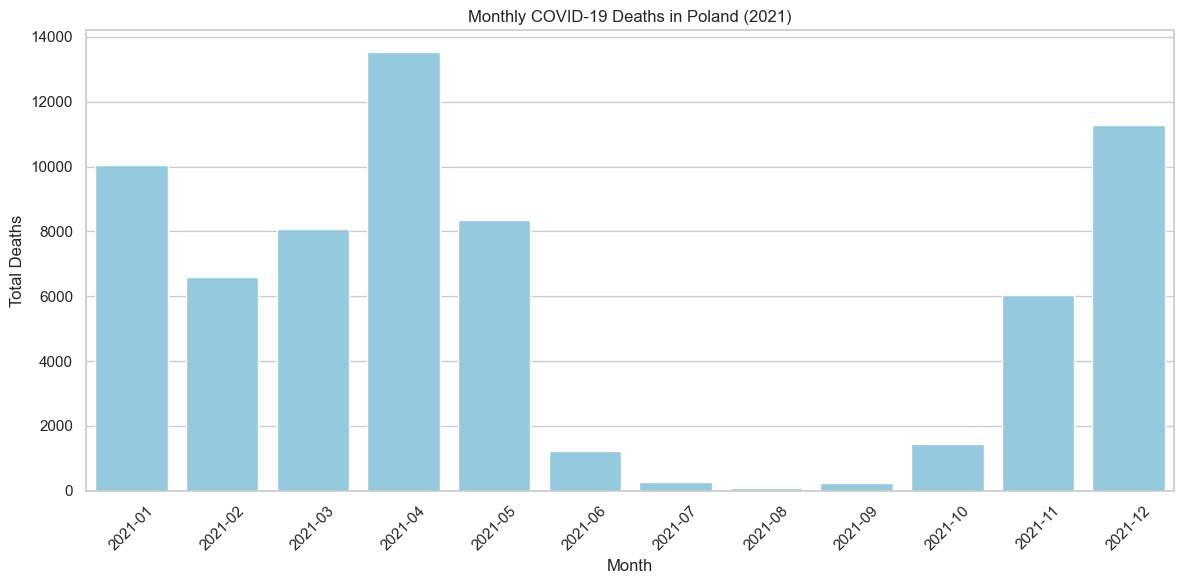

In [ ]:
df = pd.read_csv('europe_covid_cleaned.csv', usecols=['location', 'date', 'new_deaths'])
df['date'] = pd.to_datetime(df['date'])
df = df[(df['location'] == 'Poland') & (df['date'].dt.year == 2021)].copy()
df['month'] = df['date'].dt.to_period('M')
monthly = df.groupby('month')['new_deaths'].sum().reset_index()

plt.figure(figsize=(12, 6))
sns.barplot(x=monthly['month'].astype(str), y=monthly['new_deaths'], color='skyblue')
plt.title('Monthly COVID-19 Deaths in Poland (2021)')
plt.xlabel('Month')
plt.ylabel('Total Deaths')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()



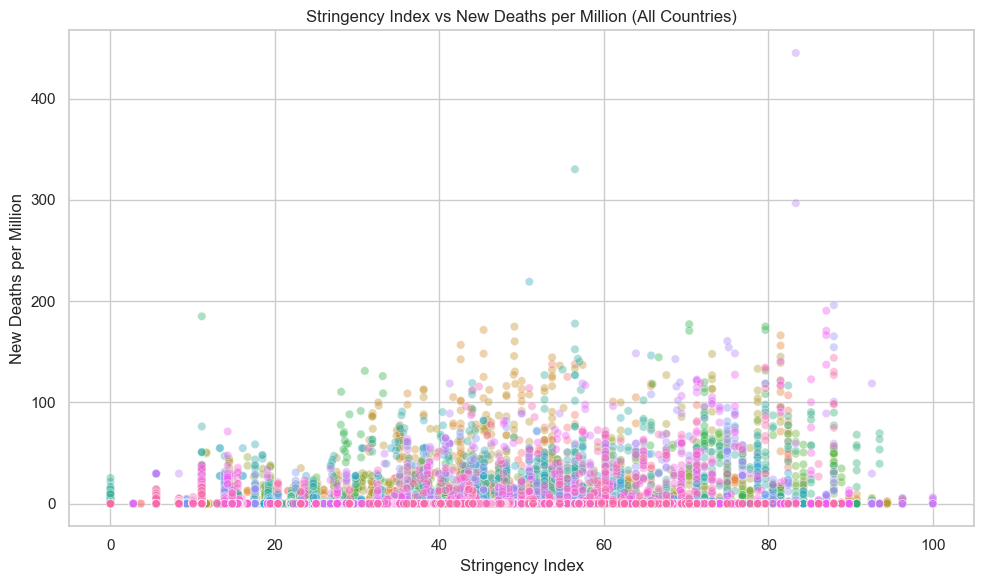

In [ ]:
df = pd.read_csv('europe_covid_cleaned.csv', usecols=['location', 'stringency_index', 'new_deaths_per_million'])
df = df.dropna(subset=['stringency_index', 'new_deaths_per_million'])

plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='stringency_index', y='new_deaths_per_million', hue='location', alpha=0.4, legend=False)
plt.title('Stringency Index vs New Deaths per Million (All Countries)')
plt.xlabel('Stringency Index')
plt.ylabel('New Deaths per Million')
plt.tight_layout()
plt.show()
